# Principal Component Analysis (PCA)

Can a set of uncorrelated weather components predict Pgen better than irradiance alone? We will use temperature, wind, direct normal irradiance, cloud cover, and sun position. All of these variables influence how much solar radiation reaches the panels. PCA will turn these into uncorrelated components. We can then regress Pgen on these components. This is called principal component regression (PCR). 

## Imports

In [80]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

## Load Data

In [68]:
base_dir = os.path.join(os.getcwd(), '..') 
processed_data_dir = os.path.join(base_dir, 'processed_data')

open_meteo_filepath = os.path.join(processed_data_dir, 'open_meteo_processed_data.csv')
open_meteo_df = pd.read_csv(open_meteo_filepath, parse_dates=['datetime'])

ausgrid_filepath = os.path.join(processed_data_dir, 'ausgrid_processed_data.csv')
ausgrid_df = pd.read_csv(ausgrid_filepath, parse_dates=['datetime'])

In [54]:
print(f'Open-Meteo Dataset Columns: {open_meteo_df.columns.tolist()}')
print(f'Ausgrid Dataset Columns: {ausgrid_df.columns.tolist()}')

Open-Meteo Dataset Columns: ['datetime', 'temperature_2m', 'wind_speed_10m', 'shortwave_radiation', 'cloud_cover', 'direct_normal_irradiance', 'diffuse_radiation', 'sunshine_duration', 'solar_zenith', 'solar_azimuth']
Ausgrid Dataset Columns: ['Customer', 'Generator Capacity', 'Postcode', 'datetime', 'Pload', 'Pgen', 'Pnet']


### Prepare data
filter to daylight rows only (solar_zenith < 90)
Also, use cos(solar_zenith), turn azimuth hour and day into sin/cos pairs (cyclical)
Remove duplicate weather rows (all customers have same weather)

In [69]:
# Keep daylight rows only (sun above the horizon)
open_meteo_df = open_meteo_df[open_meteo_df["solar_zenith"] < 90].copy()

# Zenith: replace with its cosine (1 = sun overhead, 0 = on the horizon)
open_meteo_df["cos_solar_zenith"] = np.cos(np.radians(open_meteo_df["solar_zenith"]))
open_meteo_df = open_meteo_df.drop(columns=["solar_zenith"])

# Azimuth -> sin/cos (degrees)
az = np.deg2rad(open_meteo_df["solar_azimuth"])
open_meteo_df["azimuth_sin"], open_meteo_df["azimuth_cos"] = np.sin(az), np.cos(az)
open_meteo_df = open_meteo_df.drop(columns="solar_azimuth")

# Datetime -> hour and day of year
datetimes = pd.to_datetime(open_meteo_df["datetime"])

# Hour/day -> sin/cos
open_meteo_df["hour_sin"] = np.sin(2*np.pi*datetimes.dt.hour/24)
open_meteo_df["hour_cos"] = np.cos(2*np.pi*datetimes.dt.hour/24)
open_meteo_df["day_sin"] = np.sin(2*np.pi*datetimes.dt.dayofyear/365.25)
open_meteo_df["day_cos"] = np.cos(2*np.pi*datetimes.dt.dayofyear/365.25)

display(open_meteo_df.head())


,datetime,temperature_2m,wind_speed_10m,shortwave_radiation,cloud_cover,direct_normal_irradiance,diffuse_radiation,sunshine_duration,cos_solar_zenith,azimuth_sin,azimuth_cos,hour_sin,hour_cos,day_sin,day_cos
15,2010-07-01 07:30:00,2.3,7.35,0.0,71.5,0.00,0.0,0.000,0.076622,0.850371,0.526183,0.965926,-0.258819,0.010751,-0.999942
16,2010-07-01 08:00:00,2.3,7.20,0.0,70.0,0.00,0.0,0.000,0.165989,0.805337,0.592817,0.866025,-0.500000,0.010751,-0.999942
17,2010-07-01 08:30:00,4.2,7.70,22.5,68.5,97.70,12.5,1617.505,0.248772,0.750466,0.660909,0.866025,-0.500000,0.010751,-0.999942
18,2010-07-01 09:00:00,6.1,8.20,45.0,67.0,195.40,25.0,3235.010,0.323556,0.683934,0.729544,0.707107,-0.707107,0.010751,-0.999942
19,2010-07-01 09:30:00,6.4,7.55,116.5,65.5,328.85,49.5,3417.505,0.389062,0.603926,0.797040,0.707107,-0.707107,0.010751,-0.999942


### Training-Testing Dataset Creation

We will create two testing datasets. The first will evaluate model performance on unseen customers, using models trained to predict PV generation generally rather than for specific customers. It will hold out all three years of data for a subset of customers.

The second will evaluate model performance on unseen days for models trained separately for each customer. Its goal is to predict future generation for known customers. This dataset uses a single chronological split, so it may not include data from all seasons.

In [70]:
unseen_customer_testing_split = 0.15
unseen_datetime_testing_split = 0.15

First, we choose a subset of the customers to hold out. We want to choose a group of customers whose combined data is near the target dataset size specified by `data`. `cumulative_customer_rows` is the running total of rows for shuffled customers. This will allow us to determine how many customers to hold out so their combined rows are closest to the target test-set size.

In [71]:
data = ausgrid_df.merge(open_meteo_df, on='datetime', how='left').sort_values('datetime')
data = data.drop(columns = ['Postcode', 'Pload', 'Pnet'])

In [72]:
data = data.dropna()
print(f'Number of Missing Values: {data.isna().sum().sum()}')

Number of Missing Values: 0


In [73]:
rng = np.random.default_rng(42)

customer_counts = data.groupby("Customer", sort=False).size()
shuffled_customers = rng.permutation(customer_counts.index.to_numpy())
customer_counts_shuffled = customer_counts.loc[shuffled_customers]
cumulative_customer_rows = customer_counts_shuffled.cumsum()

Next, we calculate the desired number of rows in the unseen-customer test set. We find how many shuffled customers give a cumulative row count closest to that target, and convert this into the number of customers to select. Finally, we select that many customers from the start of the shuffled list. Their rows become the test set.

In [74]:
customer_target_rows = unseen_customer_testing_split * len(data)
customer_count_end = (cumulative_customer_rows - customer_target_rows).abs().argmin() + 1
customer_test_customers = shuffled_customers[:customer_count_end]

display(pd.DataFrame({
    "Target rows": [customer_target_rows],
    "Actual rows": [cumulative_customer_rows.iloc[customer_count_end - 1]],
    "Customers selected": [customer_count_end],
}).style.hide(axis='index'))

print(f"Customers selected for test dataset: {sorted(map(int, customer_test_customers))}")

Target rows,Actual rows,Customers selected
1178890.650000,1179225,45


Customers selected for test dataset: [5, 7, 9, 17, 19, 29, 49, 59, 75, 77, 78, 79, 82, 86, 90, 107, 108, 113, 115, 128, 129, 130, 134, 138, 143, 145, 154, 166, 178, 181, 213, 224, 240, 241, 248, 250, 251, 256, 271, 273, 281, 287, 290, 294, 296]


Next we create a Boolean mask `True` for rows whose customer is in the test-customer list, `False` otherwise. We then copy test-customer rows into a separate dataset. We flip the mask in order to select the remaining rows. 

In [75]:
customer_test_mask = data['Customer'].isin(customer_test_customers)
customer_test_data = data.loc[customer_test_mask].copy()
remaining_data = data.loc[~customer_test_mask]

print(f"Customer test data: {len(customer_test_data):,} rows, {customer_test_data['Customer'].nunique()} customers")
print(f"Remaining data: {len(remaining_data):,} rows, {remaining_data['Customer'].nunique()} customers")

Customer test data: 1,179,225 rows, 45 customers
Remaining data: 6,680,046 rows, 255 customers


In [76]:
rows_per_datetime = remaining_data.groupby('datetime', sort=True).size()
cumulative_tail_rows = rows_per_datetime.iloc[::-1].cumsum()
datetime_target_rows = (unseen_datetime_testing_split / (1 - unseen_customer_testing_split)) * len(remaining_data)
datetime_start = (cumulative_tail_rows.sub(datetime_target_rows).abs().idxmin())

Next, we select rows on or after the start timestamp. Early rows become the training dataset. Because the training dataset now has fewer unique datetimes than the unseen customer testing set, we further trim the unseen customer testing set. Finally, we take the only the data with both unseen customers and unseen timestamps as our third testing dataset.

In [77]:
datetime_test_mask = remaining_data['datetime'] >= datetime_start
datetime_test_data = remaining_data.loc[datetime_test_mask].copy()
train_data = remaining_data.loc[~datetime_test_mask].copy()

# Keep unseen-customer test rows only for timestamps also present in the training set
train_timestamps = train_data['datetime'].unique()
customer_test_data = customer_test_data.loc[
    customer_test_data['datetime'].isin(train_timestamps)].copy()

# Hold out rows for unseen customers at timestamps excluded from training,
customer_datetime_test_mask = (
    data['Customer'].isin(customer_test_customers)
    & ~data['datetime'].isin(train_timestamps)
)
unseen_customer_datetime_test_data = data.loc[customer_datetime_test_mask].copy()

display(pd.DataFrame({
    'Dataset': [
        'Train',
        'Unseen datetime test',
        'Unseen customer test',
        'Unseen customer + datetime test'
    ],
    'Rows': [
        len(train_data),
        len(datetime_test_data),
        len(customer_test_data),
        len(unseen_customer_datetime_test_data)
    ],
    'Customers': [
        train_data['Customer'].nunique(),
        datetime_test_data['Customer'].nunique(),
        customer_test_data['Customer'].nunique(),
        unseen_customer_datetime_test_data['Customer'].nunique()
    ],
    'Unique timestamps': [
        train_data['datetime'].nunique(),
        datetime_test_data['datetime'].nunique(),
        customer_test_data['datetime'].nunique(),
        unseen_customer_datetime_test_data['datetime'].nunique()
    ],
    'Missing values': [
        train_data.isna().sum().sum(),
        datetime_test_data.isna().sum().sum(),
        customer_test_data.isna().sum().sum(),
        unseen_customer_datetime_test_data.isna().sum().sum()
    ]
}).style.hide(axis='index'))

Dataset,Rows,Customers,Unique timestamps,Missing values
Train,5501309,255,21581,0
Unseen datetime test,1178737,255,4624,0
Unseen customer test,971145,45,21581,0
Unseen customer + datetime test,208080,45,4624,0


## Data Normalization

In [78]:
# Columns that are identifiers or the target, not model inputs
exclude_cols = ['Customer', 'datetime', 'Pgen']
feature_cols = [c for c in train_data.select_dtypes('number').columns
                if c not in exclude_cols]

# Fit on training data only
scaler = StandardScaler()
train_data[feature_cols] = scaler.fit_transform(train_data[feature_cols])
display(train_data.head())

# Apply the same scaling to each test set
for test_df in (datetime_test_data, customer_test_data, unseen_customer_datetime_test_data):
    test_df[feature_cols] = scaler.transform(test_df[feature_cols])
    display(test_df.head())

,Customer,Generator Capacity,datetime,Pgen,temperature_2m,wind_speed_10m,shortwave_radiation,cloud_cover,direct_normal_irradiance,diffuse_radiation,sunshine_duration,cos_solar_zenith,azimuth_sin,azimuth_cos,hour_sin,hour_cos,day_sin,day_cos
3520863,68,-0.184222,2010-07-01 07:30:00,0.000,-2.840089,-0.695632,-1.396633,0.463886,-1.399252,-1.427353,-1.95841,-1.617107,1.063239,0.214337,1.401511,1.035642,0.219308,-1.543322
12779871,244,0.359186,2010-07-01 07:30:00,0.000,-2.840089,-0.695632,-1.396633,0.463886,-1.399252,-1.427353,-1.95841,-1.617107,1.063239,0.214337,1.401511,1.035642,0.219308,-1.543322
14252895,272,-0.267824,2010-07-01 07:30:00,0.001,-2.840089,-0.695632,-1.396633,0.463886,-1.399252,-1.427353,-1.95841,-1.617107,1.063239,0.214337,1.401511,1.035642,0.219308,-1.543322
15305055,292,-0.664930,2010-07-01 07:30:00,0.000,-2.840089,-0.695632,-1.396633,0.463886,-1.399252,-1.427353,-1.95841,-1.617107,1.063239,0.214337,1.401511,1.035642,0.219308,-1.543322
3363039,65,-0.163322,2010-07-01 07:30:00,0.020,-2.840089,-0.695632,-1.396633,0.463886,-1.399252,-1.427353,-1.95841,-1.617107,1.063239,0.214337,1.401511,1.035642,0.219308,-1.543322


,Customer,Generator Capacity,datetime,Pgen,temperature_2m,wind_speed_10m,shortwave_radiation,cloud_cover,direct_normal_irradiance,diffuse_radiation,sunshine_duration,cos_solar_zenith,azimuth_sin,azimuth_cos,hour_sin,hour_cos,day_sin,day_cos
9193185,175,-0.163322,2012-12-18 16:30:00,0.363,1.361082,1.456646,1.363427,-1.394196,1.33312,0.126723,0.611176,0.539734,-1.249272,-1.175321,-1.197177,0.340587,-0.095643,1.292844
7930593,151,-0.664930,2012-12-18 16:30:00,0.019,1.361082,1.456646,1.363427,-1.394196,1.33312,0.126723,0.611176,0.539734,-1.249272,-1.175321,-1.197177,0.340587,-0.095643,1.292844
14611809,278,0.359186,2012-12-18 16:30:00,0.244,1.361082,1.456646,1.363427,-1.394196,1.33312,0.126723,0.611176,0.539734,-1.249272,-1.175321,-1.197177,0.340587,-0.095643,1.292844
13401825,255,0.526389,2012-12-18 16:30:00,0.656,1.361082,1.456646,1.363427,-1.394196,1.33312,0.126723,0.611176,0.539734,-1.249272,-1.175321,-1.197177,0.340587,-0.095643,1.292844
13717473,261,-0.664930,2012-12-18 16:30:00,0.319,1.361082,1.456646,1.363427,-1.394196,1.33312,0.126723,0.611176,0.539734,-1.249272,-1.175321,-1.197177,0.340587,-0.095643,1.292844


,Customer,Generator Capacity,datetime,Pgen,temperature_2m,wind_speed_10m,shortwave_radiation,cloud_cover,direct_normal_irradiance,diffuse_radiation,sunshine_duration,cos_solar_zenith,azimuth_sin,azimuth_cos,hour_sin,hour_cos,day_sin,day_cos
6992991,134,-0.184222,2010-07-01 07:30:00,0.000,-2.840089,-0.695632,-1.396633,0.463886,-1.399252,-1.427353,-1.95841,-1.617107,1.063239,0.214337,1.401511,1.035642,0.219308,-1.543322
7203423,138,2.449219,2010-07-01 07:30:00,0.013,-2.840089,-0.695632,-1.396633,0.463886,-1.399252,-1.427353,-1.95841,-1.617107,1.063239,0.214337,1.401511,1.035642,0.219308,-1.543322
206559,5,-0.685830,2010-07-01 07:30:00,0.000,-2.840089,-0.695632,-1.396633,0.463886,-1.399252,-1.427353,-1.95841,-1.617107,1.063239,0.214337,1.401511,1.035642,0.219308,-1.543322
5888223,113,-0.163322,2010-07-01 07:30:00,0.000,-2.840089,-0.695632,-1.396633,0.463886,-1.399252,-1.427353,-1.95841,-1.617107,1.063239,0.214337,1.401511,1.035642,0.219308,-1.543322
8045151,154,-0.685830,2010-07-01 07:30:00,0.000,-2.840089,-0.695632,-1.396633,0.463886,-1.399252,-1.427353,-1.95841,-1.617107,1.063239,0.214337,1.401511,1.035642,0.219308,-1.543322


,Customer,Generator Capacity,datetime,Pgen,temperature_2m,wind_speed_10m,shortwave_radiation,cloud_cover,direct_normal_irradiance,diffuse_radiation,sunshine_duration,cos_solar_zenith,azimuth_sin,azimuth_cos,hour_sin,hour_cos,day_sin,day_cos
9508833,181,-0.476827,2012-12-18 16:30:00,0.375,1.361082,1.456646,1.363427,-1.394196,1.33312,0.126723,0.611176,0.539734,-1.249272,-1.175321,-1.197177,0.340587,-0.095643,1.292844
3932385,75,6.629285,2012-12-18 16:30:00,3.075,1.361082,1.456646,1.363427,-1.394196,1.33312,0.126723,0.611176,0.539734,-1.249272,-1.175321,-1.197177,0.340587,-0.095643,1.292844
355041,7,0.526389,2012-12-18 16:30:00,0.500,1.361082,1.456646,1.363427,-1.394196,1.33312,0.126723,0.611176,0.539734,-1.249272,-1.175321,-1.197177,0.340587,-0.095643,1.292844
881121,17,0.202434,2012-12-18 16:30:00,0.663,1.361082,1.456646,1.363427,-1.394196,1.33312,0.126723,0.611176,0.539734,-1.249272,-1.175321,-1.197177,0.340587,-0.095643,1.292844
6773217,129,-0.581329,2012-12-18 16:30:00,0.244,1.361082,1.456646,1.363427,-1.394196,1.33312,0.126723,0.611176,0.539734,-1.249272,-1.175321,-1.197177,0.340587,-0.095643,1.292844


## Data Exploration: Correlation Heatmap

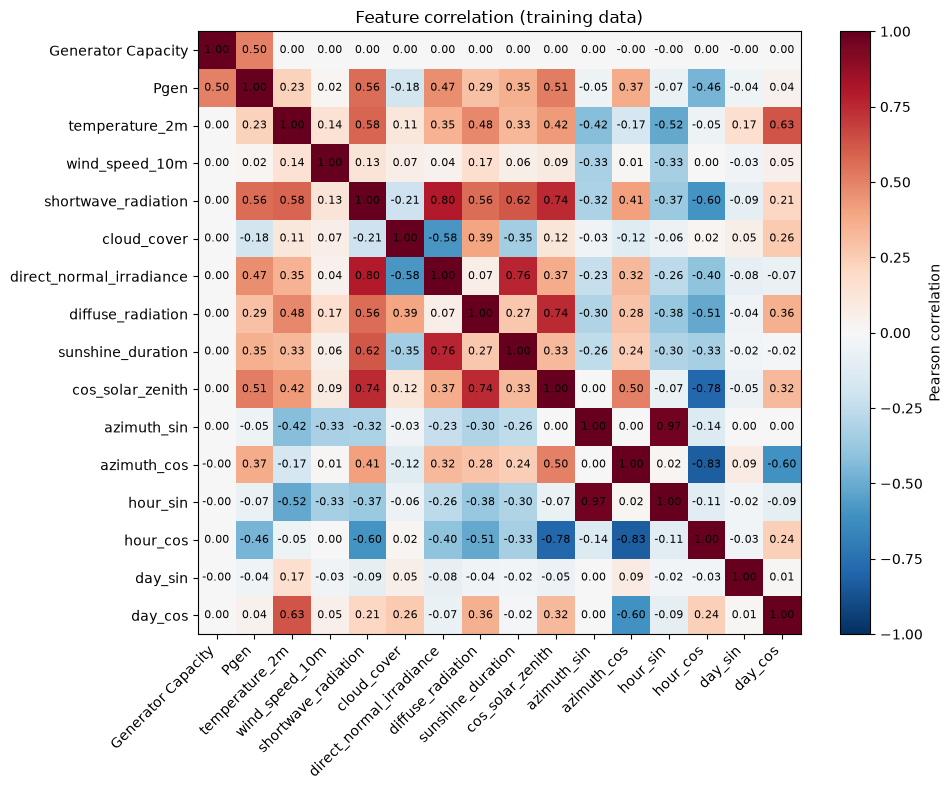

In [79]:
corr = train_data.select_dtypes('number').drop(columns=['Customer'], errors='ignore').corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax, label='Pearson correlation')
ax.set_title('Feature correlation (training data)')
plt.tight_layout()
plt.show()

The heatmap shows that Pgen is most strongly related to `shortwave_radiation` (0.56), `cos_solar_zenith` (0.51), `Generator Capacity` (0.50), and `direct_normal_irradiance` (0.47), and is negatively related to `hour_cos` (-0.46), which is lowest at midday. `Cloud cover` has a weak negative relationship with generation (-0.18) and a stronger one with `direct irradiance` (-0.58), as expected. Many features are highly correlated with each other. The radiation variables and `cos_solar_zenith` correlate at 0.6–0.8, `hour_sin` is almost identical to `azimuth_sin` (0.97), and `hour_cos` closely tracks both `cos_solar_zenith` (-0.78) and `azimuth_cos` (-0.83), because clock time and sun position describe the same daily cycle. day_cos captures the seasons and is linked to temperature (0.63). Because these features overlap so much, PCA should be able to combine them into a smaller set of uncorrelated components. `Generator Capacity` is unrelated to every weather feature and will likely form its own component, while `day_sin` and `wind_speed_10m` show little relationship with anything.

## Fit PCA on the Training Data

Component,Explained variance,Cumulative
PC1,0.326,0.326
PC2,0.195,0.521
PC3,0.149,0.671
PC4,0.111,0.782
PC5,0.076,0.858
PC6,0.058,0.916
PC7,0.033,0.948
PC8,0.021,0.970
PC9,0.012,0.982
PC10,0.007,0.989


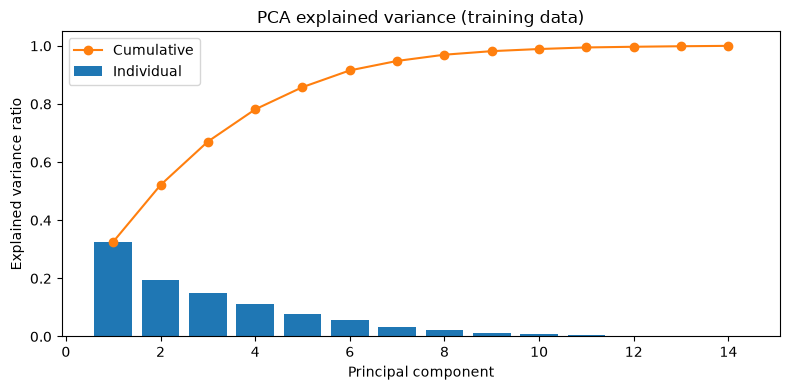

In [83]:
# PCA uses weather and sun-position features only
pca_cols = [c for c in feature_cols if c != 'Generator Capacity']

# Fit PCA on training features only (already standardized)
pca = PCA()
pca.fit(train_data[pca_cols])

# Explained variance per component
explained = pd.DataFrame({
    'Component': [f'PC{i+1}' for i in range(pca.n_components_)],
    'Explained variance': pca.explained_variance_ratio_,
    'Cumulative': np.cumsum(pca.explained_variance_ratio_)
})
display(explained.style.format({'Explained variance': '{:.3f}', 'Cumulative': '{:.3f}'}).hide(axis='index'))

# Scree plot
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, pca.n_components_ + 1), pca.explained_variance_ratio_, label='Individual')
ax.plot(range(1, pca.n_components_ + 1), np.cumsum(pca.explained_variance_ratio_), 'o-', color='C1', label='Cumulative')
ax.set_xlabel('Principal component')
ax.set_ylabel('Explained variance ratio')
ax.set_title('PCA explained variance (training data)')
ax.legend()
plt.tight_layout()
plt.show()

We choose 7 components, which retain about 95% of the variance while halving the number of inputs and removing the multicollinearity between the original features.

## Principal Component Regression

In [84]:
from sklearn.linear_model import LinearRegression

n_components = 7

def get_pc_features(df):
    """First k principal components plus Generator Capacity."""
    pcs = pca.transform(df[pca_cols])[:, :n_components]
    return np.column_stack([pcs, df['Generator Capacity'].to_numpy()])

# Fit the global model on all training customers
global_model = LinearRegression().fit(get_pc_features(train_data), train_data['Pgen'])

# Fit the per-customer models (components only: capacity is constant within a customer)
customer_models = {}
for customer, group in train_data.groupby('Customer'):
    pcs = pca.transform(group[pca_cols])[:, :n_components]
    customer_models[customer] = LinearRegression().fit(pcs, group['Pgen'])

For each customer, the prediction uses that customer's own model if one was trained, and the global model otherwise (so for unseen customers). Negative predictions are clipped to zero:

In [85]:
def predict_pcr(test_data):
    predictions = test_data.copy()
    predictions['Pgen_Pred_pcr'] = global_model.predict(get_pc_features(predictions))

    for customer, idx in predictions.groupby('Customer').groups.items():
        if customer in customer_models:
            pcs = pca.transform(predictions.loc[idx, pca_cols])[:, :n_components]
            predictions.loc[idx, 'Pgen_Pred_pcr'] = customer_models[customer].predict(pcs)

    predictions['Pgen_Pred_pcr'] = predictions['Pgen_Pred_pcr'].clip(lower=0)
    return predictions

test_predictions = {
    "Unseen datetimes": predict_pcr(datetime_test_data),
    "Unseen customers": predict_pcr(customer_test_data),
    "Unseen customers + datetimes": predict_pcr(unseen_customer_datetime_test_data)}

pcr_metrics = []
for dataset_name, predictions in test_predictions.items():
    valid = predictions[["Pgen", "Pgen_Pred_pcr"]].dropna()
    errors = valid["Pgen"] - valid["Pgen_Pred_pcr"]
    pcr_metrics.append({
        "Test set": dataset_name,
        "MAE": errors.abs().mean(),
        "RMSE": np.sqrt((errors ** 2).mean()),
        "Rows evaluated": len(valid),
    })

display(pd.DataFrame(pcr_metrics).style.format({
    "MAE": "{:.4f}", "RMSE": "{:.4f}", "Rows evaluated": "{:,}",
}).hide(axis="index"))


Test set,MAE,RMSE,Rows evaluated
Unseen datetimes,0.0892,0.1398,"1,178,737"
Unseen customers,0.1413,0.2656,"971,145"
Unseen customers + datetimes,0.1384,0.2630,"208,080"
